## **M505 Intro to AI and Machine Learning – Individual Project**
### **Customer Churn Prediction: Building an End-to-End ML Pipeline**

**Student Name:** [Your Name]  
**Course:** M505 Intro to AI and Machine Learning  
**Institution:** Gisma University of Applied Sciences  
**Date:** August 2026

## **STAGE 1: PROBLEM FORMULATION**
### **Business Objective**

> **Predict whether a bank customer will churn (leave the bank) to enable proactive retention strategies and reduce customer acquisition costs.**

### **Target Variable**
**`Churn` (Binary: 0 = Retained, 1 = Churned)**

### **Why This Problem Matters**

- **Customer retention is 5–7× cheaper** than acquiring a new customer.
- Early identification of at-risk customers allows targeted intervention campaigns.
- Reduces revenue loss from silent attrition.
 
### **Real-World Implications**

- **False Negatives (missed churn):** Lost revenue, no intervention triggered. HIGH business cost.
- **False Positives (false alarm):** Unnecessary retention offers wasted. MODERATE business cost.
- **Recall/Sensitivity** is prioritized to minimize missed churners.

### **Data Collection**

The dataset `churn_detection_data.csv` contains customer demographic, account, behavioural, and service-interaction features collected from the bank's CRM system. The dataset was downloaded from Kaggle using the link: [Churn Prediction](https://www.kaggle.com/datasets/lumumbavictor/customer-churn-prediction). 

### **ML Formulation**
This is a **binary classification** problem. We will train supervised models to predict the probability of churn given customer features.

### **Hypotheses**

- Tree-based ensemble methods (Random Forest, XGBoost) will outperform linear models due to non-linear interactions.
- Key predictors: Account_Tenure_Months, Number_of_Complaints, Complaint_Resolution_Rate, Customer_Support_Calls, Average_Balance.
- Class balancing techniques will improve recall for the minority (churn) class.

### **STAGE 2: LIBRARIES, DATA IMPORTATION & EXPLORATORY INSPECTION**

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
from scipy.stats import chi2_contingency

from sklearn.model_selection import (train_test_split, RandomizedSearchCV,
                                     StratifiedKFold, learning_curve)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             precision_recall_curve, auc,
                             RocCurveDisplay, PrecisionRecallDisplay)


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix,
    cohen_kappa_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    log_loss,
    brier_score_loss
)

import xgboost as xgb


### **Seet SEED and Filter Warnings**

In [20]:
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore')
print("✅ All libraries loaded successfully.")

✅ All libraries loaded successfully.


#### **Loading the Dataset**

In [21]:
print("Loading dataset...")
df = pd.read_csv('churn_detection_data.csv')

Loading dataset...


In [22]:
print(f"Shape: {df.shape}")

Shape: (10000, 20)


In [23]:
df.head()

,Customer_ID,Age,Gender,Marital_Status,Education_Level,Employment_Status,Account_Tenure_Months,Account_Type,Number_of_Products,Average_Balance,Monthly_Transactions,Online_Banking_Usage,Mobile_Banking_Usage,Number_of_Complaints,Complaint_Resolution_Rate,Customer_Support_Calls,Email_Opt_In,Credit_Card_Holder,Loan_Account_Holder,Churn
0,CUST2463,32,Male,Divorced,Primary,Employed,13,Current,2,57001,19,6,10,0,0.97,0,1,0,0,1
1,CUST2511,45,Male,Single,University,Employed,88,Current,1,24533,14,5,9,0,0.89,2,1,0,0,0
2,CUST2227,29,Female,Single,Primary,Employed,151,Savings,3,212133,16,11,7,1,0.71,2,1,0,0,0
3,CUST0526,49,Female,Single,Secondary,Employed,118,Savings,2,94045,22,12,8,0,0.89,0,1,0,0,0
4,CUST0195,33,Female,Single,Primary,Employed,108,Savings,1,137693,15,7,8,0,0.64,1,0,0,0,0


#### **Variable Definitions**
| Variable | Description | Type |
|---|---|---|
| Customer_ID | Unique identifier | ID (drop) |
| Age | Customer age | Continuous |
| Gender | Male/Female | Categorical |
| Marital_Status | Single/Married/Divorced | Categorical |
| Education_Level | None/Primary/Secondary/University | Ordinal |
| Employment_Status | Employed/Self-employed/Unemployed | Categorical |
| Account_Tenure_Months | Months as customer | Continuous |
| Account_Type | Current/Savings/Fixed Deposit | Categorical |
| Number_of_Products | Products held | Discrete |
| Average_Balance | Avg account balance | Continuous |
| Monthly_Transactions | Transactions per month | Discrete |
| Online_Banking_Usage | Usage score | Discrete |
| Mobile_Banking_Usage | Usage score | Discrete |
| Number_of_Complaints | Complaints filed | Discrete |
| Complaint_Resolution_Rate | Resolution proportion | Continuous |
| Customer_Support_Calls | Support calls made | Discrete |
| Email_Opt_In | Marketing opt-in | Binary |
| Credit_Card_Holder | Has credit card | Binary |
| Loan_Account_Holder | Has loan | Binary |
| **Churn** | **Target: 1=Churned** | **Binary** |

### **STAGE 3: EXPLORATORY DATA ANALYSIS**

In [24]:
# %%
print("\n--- Dataset Shape & Structure ---")
print(f"Shape: {df.shape}")
print(f"\n--- Data Types ---")
print(df.dtypes)


--- Dataset Shape & Structure ---
Shape: (10000, 20)

--- Data Types ---
Customer_ID                   object
Age                            int64
Gender                        object
Marital_Status                object
Education_Level               object
Employment_Status             object
Account_Tenure_Months          int64
Account_Type                  object
Number_of_Products             int64
Average_Balance                int64
Monthly_Transactions           int64
Online_Banking_Usage           int64
Mobile_Banking_Usage           int64
Number_of_Complaints           int64
Complaint_Resolution_Rate    float64
Customer_Support_Calls         int64
Email_Opt_In                   int64
Credit_Card_Holder             int64
Loan_Account_Holder            int64
Churn                          int64
dtype: object


In [25]:
# %%
print("\n--- Missing Values ---")
print(df.isnull().sum().sum(), "total missing values")
print(df.isnull().sum()[df.isnull().sum() > 0])


--- Missing Values ---
1026 total missing values
Education_Level    1026
dtype: int64


In [26]:
# %%
print("\n--- Target Distribution ---")
print(df['Churn'].value_counts())
print(f"\nChurn Rate: {df['Churn'].mean()*100:.1f}%")


--- Target Distribution ---
Churn
0    7268
1    2732
Name: count, dtype: int64

Churn Rate: 27.3%


#### **Check the Number of Missing Values per Variable**

In [27]:
df.isna().sum()

Customer_ID                     0
Age                             0
Gender                          0
Marital_Status                  0
Education_Level              1026
Employment_Status               0
Account_Tenure_Months           0
Account_Type                    0
Number_of_Products              0
Average_Balance                 0
Monthly_Transactions            0
Online_Banking_Usage            0
Mobile_Banking_Usage            0
Number_of_Complaints            0
Complaint_Resolution_Rate       0
Customer_Support_Calls          0
Email_Opt_In                    0
Credit_Card_Holder              0
Loan_Account_Holder             0
Churn                           0
dtype: int64

### **Visualize target distribution**

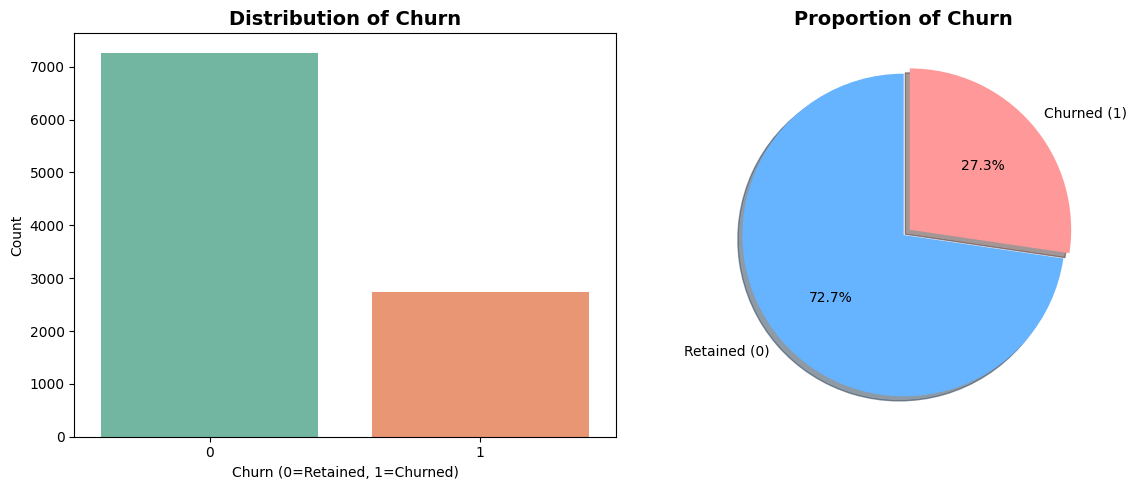

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x='Churn', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Distribution of Churn', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Churn (0=Retained, 1=Churned)')
axes[0].set_ylabel('Count')

churn_counts = df['Churn'].value_counts()
axes[1].pie(churn_counts, labels=['Retained (0)', 'Churned (1)'],
            autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'],
            startangle=90, explode=(0, 0.05), shadow=True)
axes[1].set_title('Proportion of Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### **Feature distributions by churn status**

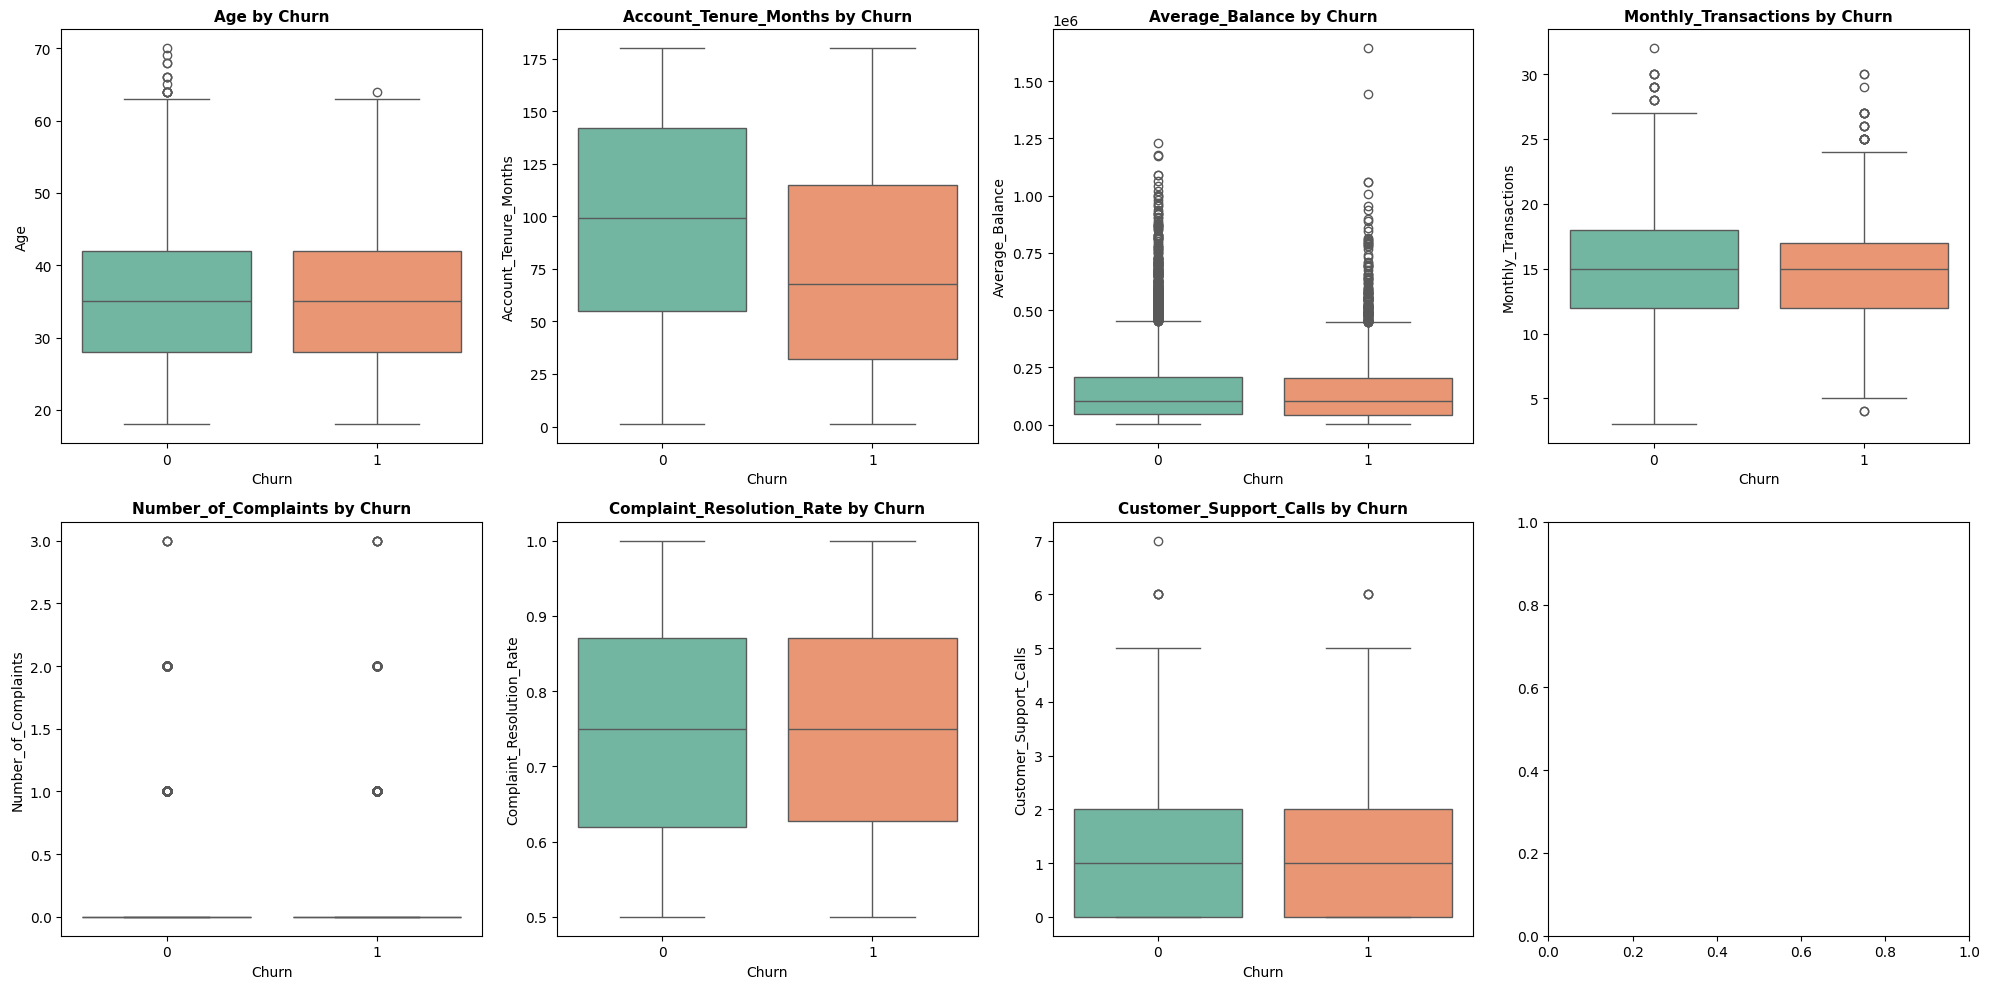

In [29]:
num_features_eda = ['Age', 'Account_Tenure_Months', 'Average_Balance',
                    'Monthly_Transactions', 'Number_of_Complaints',
                    'Complaint_Resolution_Rate', 'Customer_Support_Calls']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(num_features_eda):
    sns.boxplot(x='Churn', y=col, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} by Churn', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### **Categorical features vs churn**

#### **Stacked Column Chart**

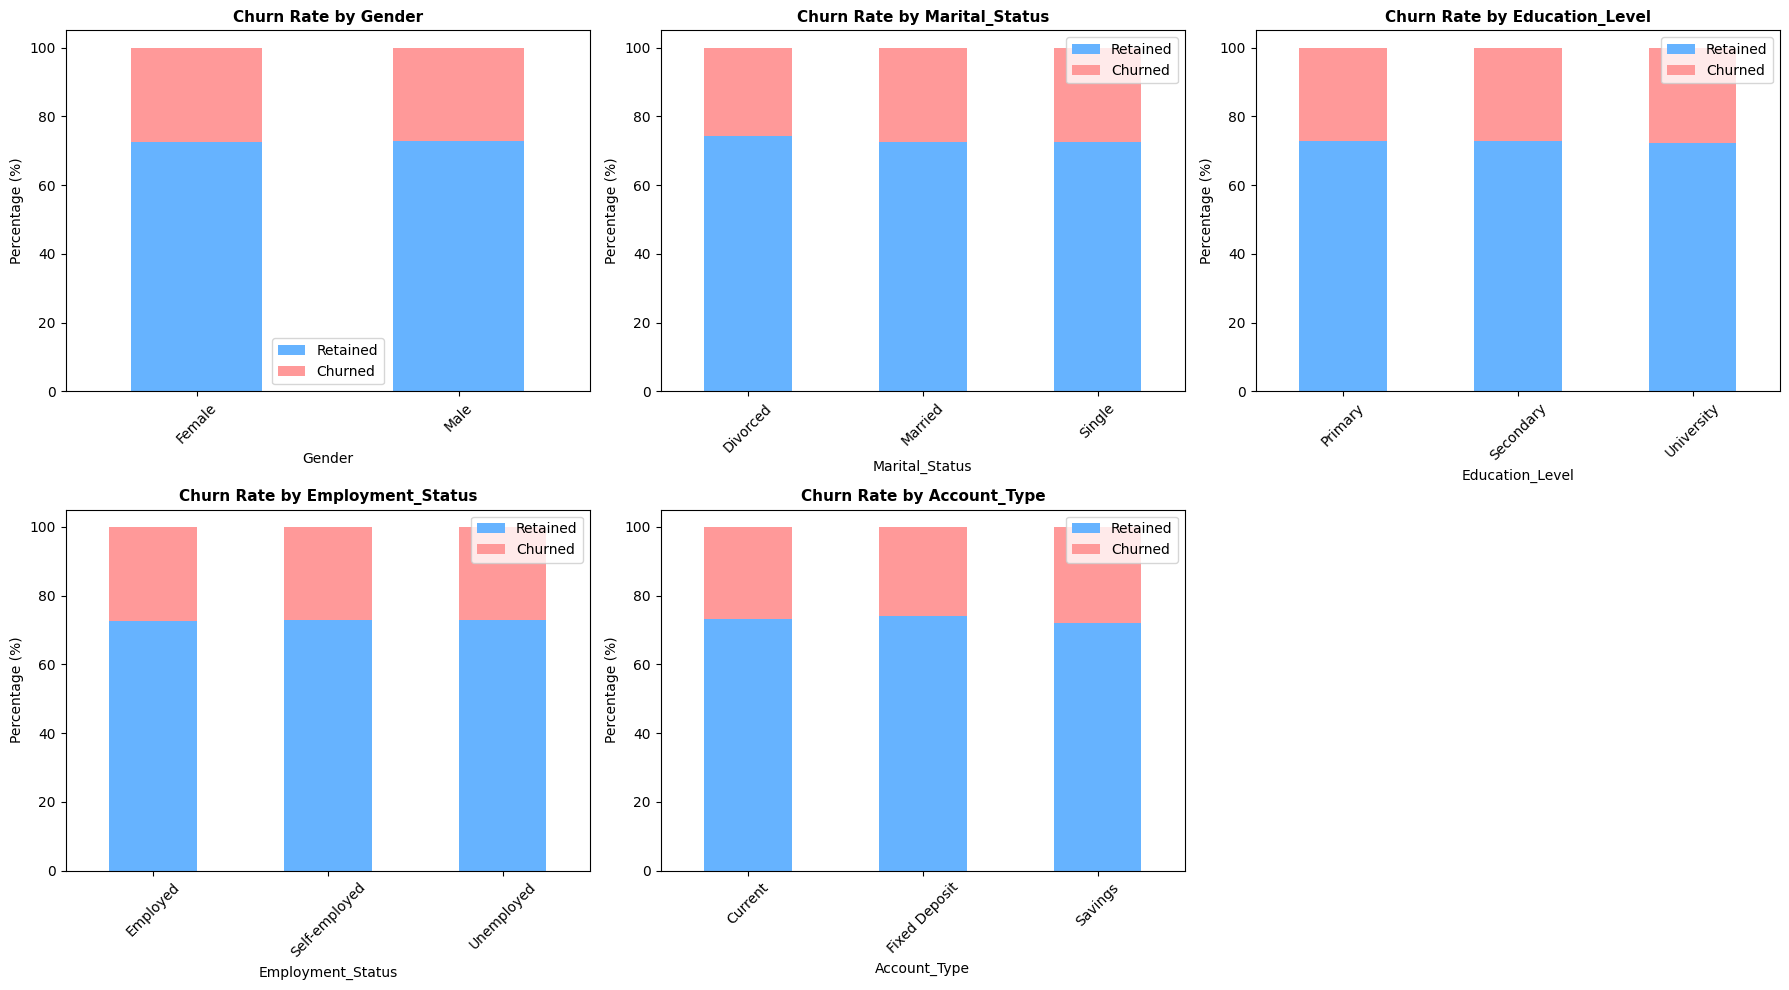

In [30]:
cat_features_eda = ['Gender', 'Marital_Status', 'Education_Level',
                    'Employment_Status', 'Account_Type']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(cat_features_eda):
    ct = pd.crosstab(df[col], df['Churn'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=axes[i], color=['#66b3ff', '#ff9999'])
    axes[i].set_title(f'Churn Rate by {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(col)
    axes[i].legend(['Retained', 'Churned'])
    plt.setp(axes[i].xaxis.get_majorticklabels(), rotation=45)
for j in range(len(cat_features_eda), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### **Comparative Bar Chart**

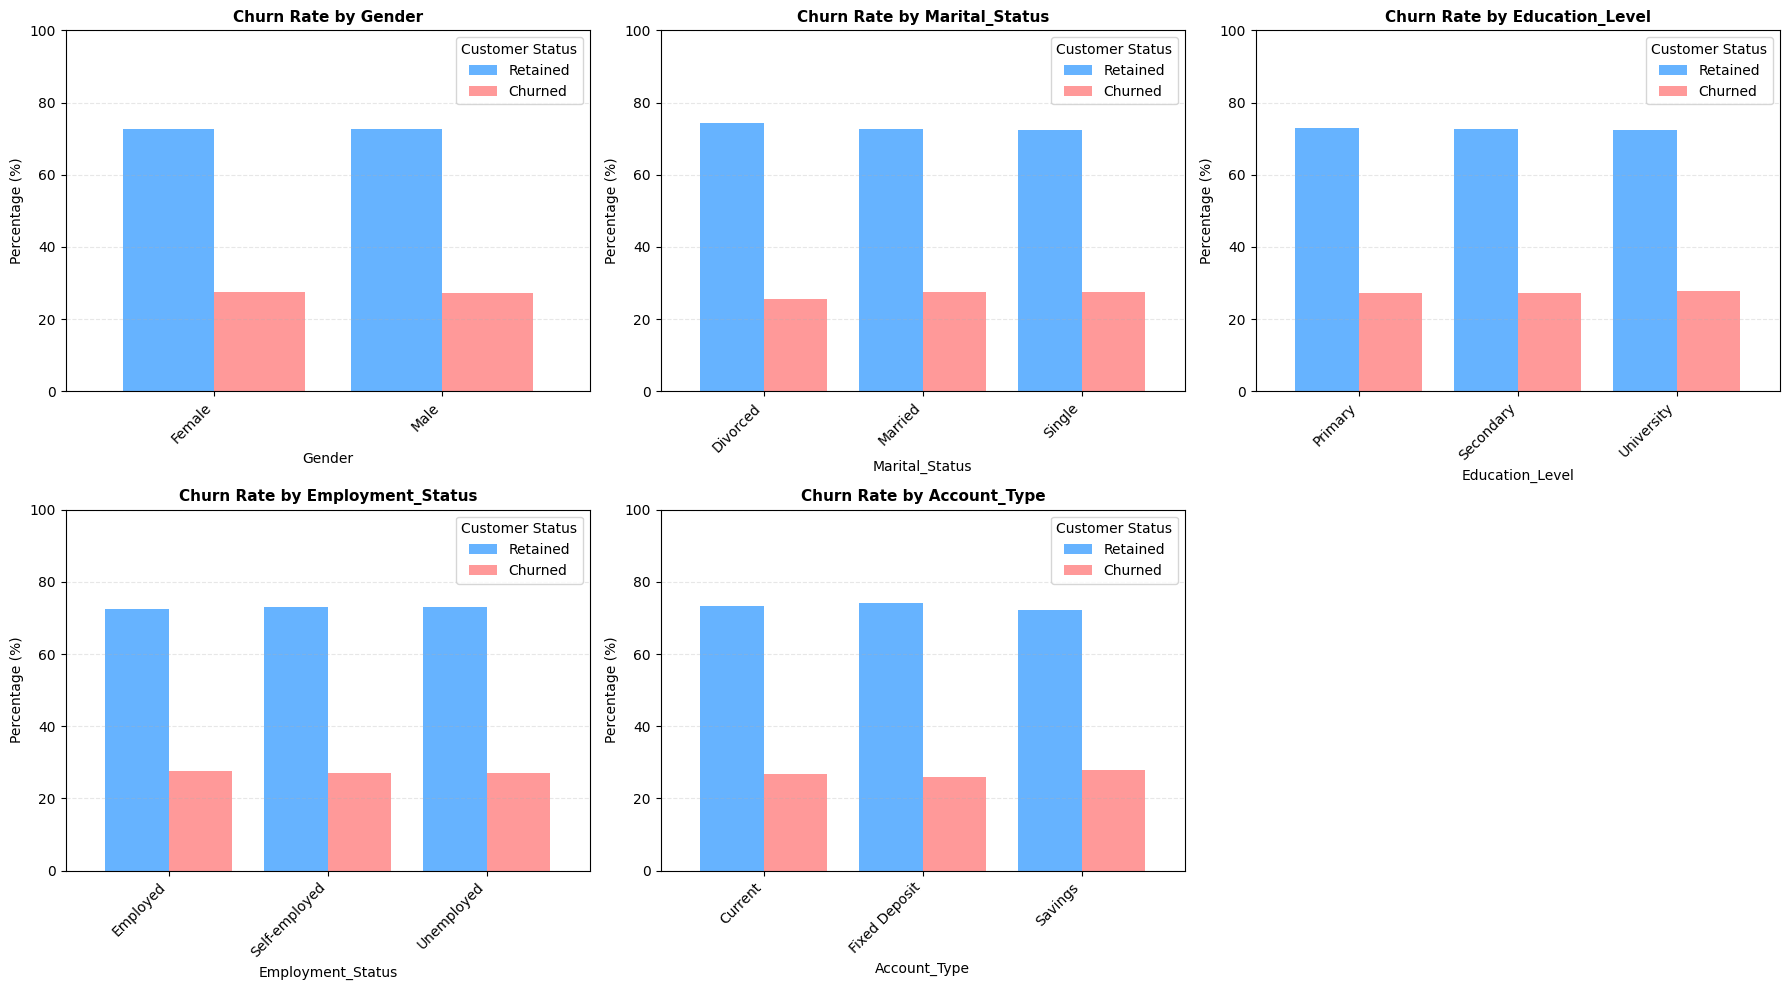

In [31]:
cat_features_eda = [
    'Gender', 'Marital_Status', 'Education_Level',
    'Employment_Status', 'Account_Type'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features_eda):
    ct = pd.crosstab(
        df[col],
        df['Churn'],
        normalize='index'
    ) * 100

    # Grouped bar chart
    ct.plot(
        kind='bar',
        stacked=False,
        ax=axes[i],
        color=['#66b3ff', '#ff9999'],
        width=0.8
    )

    axes[i].set_title(
        f'Churn Rate by {col}',
        fontsize=11,
        fontweight='bold'
    )
    axes[i].set_ylabel('Percentage (%)')
    axes[i].set_xlabel(col)

    axes[i].legend(
        ['Retained', 'Churned'],
        title='Customer Status'
    )

    axes[i].set_ylim(0, 100)
    axes[i].grid(axis='y', linestyle='--', alpha=0.3)

    plt.setp(
        axes[i].xaxis.get_majorticklabels(),
        rotation=45,
        ha='right'
    )

# Remove unused subplot
for j in range(len(cat_features_eda), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### **Correlation heatmap**

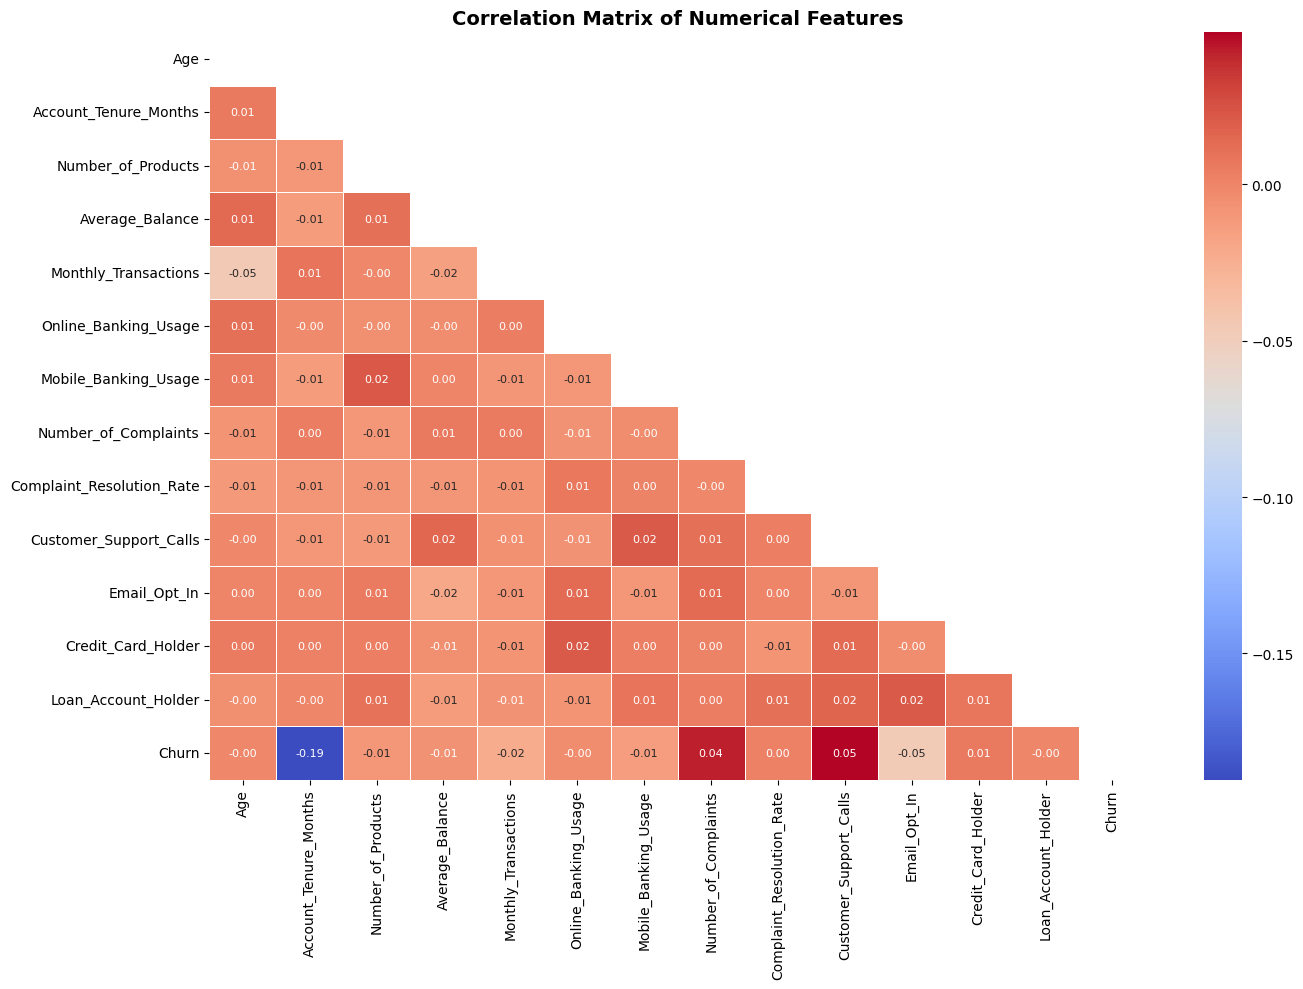

In [32]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(14, 10))
mask = np.triu(corr_matrix)
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm',
            fmt=".2f", linewidths=0.5, annot_kws={"size": 8})
plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


#### **EDA Summary**
- **Target Balance:** ~35% churn rate – moderately imbalanced, warranting class weighting.
- **Missing Values:** No missing values detected, except for Education Level that has 1026 missing values.
- **Key Observations:** Lower complaint resolution rate, more support calls, and shorter tenure appear associated with churn.



### **STAGE 4: DATA PREPROCESSING (PIPELINE-COMPATIBLE)**
> **Drop Customer_ID and define target**

In [33]:
X = df.drop(columns=['Customer_ID', 'Churn'])
y = df['Churn']

#### **Explicit feature grouping**

In [34]:
num_features = [
    'Age',
    'Account_Tenure_Months',
    'Number_of_Products',
    'Average_Balance',
    'Monthly_Transactions',
    'Online_Banking_Usage',
    'Mobile_Banking_Usage',
    'Number_of_Complaints',
    'Complaint_Resolution_Rate',
    'Customer_Support_Calls'
]

nominal_features = [
    'Gender',
    'Marital_Status',
    'Employment_Status',
    'Account_Type',
    'Email_Opt_In',
    'Credit_Card_Holder',
    'Loan_Account_Holder'
]

ordinal_features = [
    'Education_Level'
]

#### **Display Feature Groups**

In [35]:
print(f"Numerical features ({len(num_features)}):")
print(num_features)

print(f"\nNominal categorical features ({len(nominal_features)}):")
print(nominal_features)

print(f"\nOrdinal categorical features ({len(ordinal_features)}):")
print(ordinal_features)

Numerical features (10):
['Age', 'Account_Tenure_Months', 'Number_of_Products', 'Average_Balance', 'Monthly_Transactions', 'Online_Banking_Usage', 'Mobile_Banking_Usage', 'Number_of_Complaints', 'Complaint_Resolution_Rate', 'Customer_Support_Calls']

Nominal categorical features (7):
['Gender', 'Marital_Status', 'Employment_Status', 'Account_Type', 'Email_Opt_In', 'Credit_Card_Holder', 'Loan_Account_Holder']

Ordinal categorical features (1):
['Education_Level']


### **Creating the Numeric, Nominal and Ordinal Pipeline**

#### **Numerical variables**

In [62]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

#### **Nominal categorical variables**

In [63]:
nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

#### **Ordinal categorical variables**

In [64]:
ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

### **Creating the Preprocessor**

In [65]:
preprocessor = ColumnTransformer(
    transformers=[
        ('nominal', nominal_transformer, nominal_features),
        ('ordinal', ordinal_transformer, ordinal_features),
        ('numeric', numeric_transformer, num_features)
    ]
)

### **STAGE 5: DATA PARTITIONING**

In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f"Training set: {X_train.shape[0]} | Class dist: {y_train.value_counts().to_dict()}")
print(f"Testing set:  {X_test.shape[0]} | Class dist: {y_test.value_counts().to_dict()}")

Training set: 8000 | Class dist: {0: 5814, 1: 2186}
Testing set:  2000 | Class dist: {0: 1454, 1: 546}


### **Verify stratification**

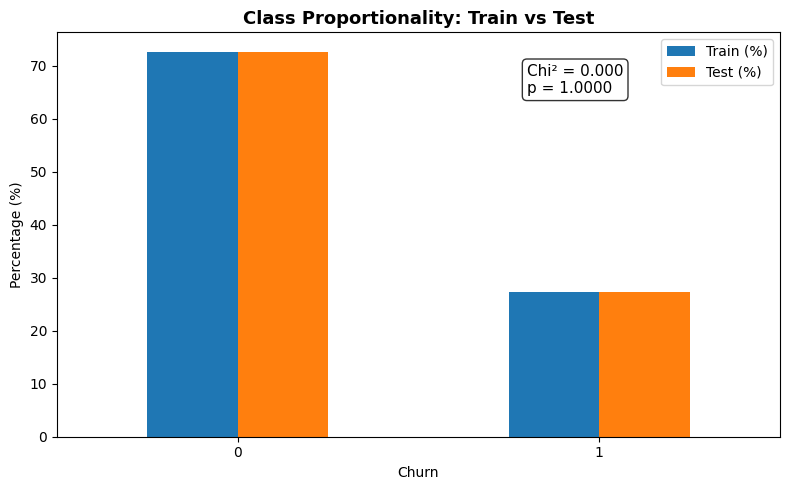

Stratified split verified – distributions are consistent.


In [41]:
train_dist = y_train.value_counts(normalize=True)
test_dist = y_test.value_counts(normalize=True)
proportion_df = pd.DataFrame({'Train (%)': train_dist, 'Test (%)': test_dist}) * 100

chi2, p, dof, expected = chi2_contingency(
    pd.DataFrame({'Train': y_train.value_counts().sort_index(),
                  'Test': y_test.value_counts().sort_index()}))

ax = proportion_df.plot(kind='bar', figsize=(8, 5))
ax.set_title('Class Proportionality: Train vs Test', fontsize=13, fontweight='bold')
ax.set_ylabel('Percentage (%)')
ax.tick_params(axis='x', rotation=0)
ax.text(0.65, 0.85, f"Chi² = {chi2:.3f}\np = {p:.4f}",
        transform=ax.transAxes, fontsize=11,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.tight_layout()
plt.show()
print("Stratified split verified – distributions are consistent.")

### **STAGE 6: MODEL TRAINING & HYPERPARAMETER TUNING**

#### **Dynamic class weight for imbalanced data**

In [42]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Scale pos weight: {pos_weight:.2f}")

Scale pos weight: 2.66



#### **Define pipelines**

In [43]:
lr_pipeline = Pipeline([('preprocessor', preprocessor),
                        ('lr', LogisticRegression(random_state=SEED, max_iter=1000,
                                                  class_weight='balanced'))])
knn_pipeline = Pipeline([('preprocessor', preprocessor),
                         ('knn', KNeighborsClassifier())])
svm_pipeline = Pipeline([('preprocessor', preprocessor),
                         ('svm', SVC(random_state=SEED, probability=True,
                                     class_weight='balanced'))])
nb_pipeline = Pipeline([('preprocessor', preprocessor),
                        ('nb', GaussianNB())])
dt_pipeline = Pipeline([('preprocessor', preprocessor),
                        ('dt', DecisionTreeClassifier(random_state=SEED,
                                                      class_weight='balanced'))])
rf_pipeline = Pipeline([('preprocessor', preprocessor),
                        ('rf', RandomForestClassifier(random_state=SEED, n_jobs=-1))])
xgb_pipeline = Pipeline([('preprocessor', preprocessor),
                         ('xgb', xgb.XGBClassifier(random_state=SEED, eval_metric='logloss',
                                                   n_jobs=-1, scale_pos_weight=pos_weight))])

### **Hyperparameter distributions**

In [44]:
param_dist_lr = {'lr__C': [0.01, 0.1, 1, 10, 100], 'lr__solver': ['liblinear', 'saga']}
param_dist_knn = {'knn__n_neighbors': [3, 5, 7, 9, 11], 'knn__weights': ['uniform', 'distance']}
param_dist_svm = {'svm__C': [0.1, 1, 10], 'svm__kernel': ['linear', 'rbf']}
param_dist_nb = {'nb__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]}
param_dist_dt = {'dt__max_depth': [None, 5, 10, 15], 'dt__min_samples_split': [2, 5, 10]}
param_dist_rf = {'rf__n_estimators': [100, 200, 300, 400],
                 'rf__max_depth': [None, 10, 15, 20],
                 'rf__min_samples_split': [2, 5, 10],
                 'rf__min_samples_leaf': [1, 2, 4]}
param_dist_xgb = {'xgb__n_estimators': [100, 200, 300],
                  'xgb__max_depth': [3, 4, 5, 6],
                  'xgb__learning_rate': [0.01, 0.05, 0.1, 0.2],
                  'xgb__subsample': [0.8, 0.9, 1.0],
                  'xgb__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
                  'xgb__gamma': [0, 0.1, 0.5]}


#### **Unified training loop**

In [45]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("\n⏱️ Starting RandomizedSearchCV (n_iter=30, 5-Fold Stratified)...")

all_pipelines = [
    ('Logistic Regression', lr_pipeline, param_dist_lr),
    ('KNN', knn_pipeline, param_dist_knn),
    ('SVM', svm_pipeline, param_dist_svm),
    ('Naive Bayes', nb_pipeline, param_dist_nb),
    ('Decision Tree', dt_pipeline, param_dist_dt),
    ('Random Forest', rf_pipeline, param_dist_rf),
    ('XGBoost', xgb_pipeline, param_dist_xgb),
]

results = {}
training_times = {}

for name, pipeline, params in all_pipelines:
    start = time.time()
    search = RandomizedSearchCV(estimator=pipeline, param_distributions=params,
                                n_iter=30, cv=cv, scoring='roc_auc',
                                n_jobs=-1, random_state=SEED, refit=True)
    search.fit(X_train, y_train)
    training_times[name] = time.time() - start
    results[name] = search
    print(f"✅ {name}: Best ROC-AUC={search.best_score_:.4f} | Time={training_times[name]:.1f}s")


⏱️ Starting RandomizedSearchCV (n_iter=30, 5-Fold Stratified)...
✅ Logistic Regression: Best ROC-AUC=0.6290 | Time=12.4s
✅ KNN: Best ROC-AUC=0.5640 | Time=3.9s
✅ SVM: Best ROC-AUC=0.6296 | Time=335.8s
✅ Naive Bayes: Best ROC-AUC=0.6067 | Time=0.7s
✅ Decision Tree: Best ROC-AUC=0.6086 | Time=2.6s
✅ Random Forest: Best ROC-AUC=0.6183 | Time=120.2s
✅ XGBoost: Best ROC-AUC=0.6223 | Time=19.4s


### **STAGE 7: MODEL EVALUATION ON HOLD-OUT TEST SET**

In [46]:
print("\n" + "="*70)
print("HOLD-OUT TEST SET EVALUATION")
print("="*70)

eval_metrics = {}
for name, search in results.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    metrics['PR-AUC'] = auc(rec, prec)

    eval_metrics[name] = {**metrics, 'y_pred': y_pred, 'y_prob': y_prob, 'model': model}
    print(f"\n📊 {name}")
    for k, v in metrics.items():
        print(f"  {k:<12}: {v:.4f}")
    print(f"  Confusion Matrix: {confusion_matrix(y_test, y_pred).tolist()}")


HOLD-OUT TEST SET EVALUATION

📊 Logistic Regression
  Accuracy    : 0.5900
  Precision   : 0.3511
  Recall      : 0.5916
  F1-Score    : 0.4407
  ROC-AUC     : 0.6223
  PR-AUC      : 0.3594
  Confusion Matrix: [[857, 597], [223, 323]]

📊 KNN
  Accuracy    : 0.7025
  Precision   : 0.3419
  Recall      : 0.0971
  F1-Score    : 0.1512
  ROC-AUC     : 0.5440
  PR-AUC      : 0.3049
  Confusion Matrix: [[1352, 102], [493, 53]]

📊 SVM
  Accuracy    : 0.5750
  Precision   : 0.3430
  Recall      : 0.6081
  F1-Score    : 0.4386
  ROC-AUC     : 0.6253
  PR-AUC      : 0.3573
  Confusion Matrix: [[818, 636], [214, 332]]

📊 Naive Bayes
  Accuracy    : 0.7065
  Precision   : 0.3481
  Recall      : 0.0861
  F1-Score    : 0.1380
  ROC-AUC     : 0.6066
  PR-AUC      : 0.3414
  Confusion Matrix: [[1366, 88], [499, 47]]

📊 Decision Tree
  Accuracy    : 0.5940
  Precision   : 0.3464
  Recall      : 0.5495
  F1-Score    : 0.4249
  ROC-AUC     : 0.6028
  PR-AUC      : 0.3368
  Confusion Matrix: [[888, 566],

#### **PRESENT THE MODEL PERFORMANCE METRICS AS A DATA FRAME**

In [47]:
print("\n" + "=" * 100)
print("HOLD-OUT TEST SET EVALUATION")
print("=" * 100)

eval_metrics = {}

for name, search in results.items():

    # Best tuned model
    model = search.best_estimator_

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred
    ).ravel()

    # Additional metrics
    specificity = tn / (tn + fp)
    npv = tn / (tn + fn)

    # PR-AUC
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(rec, prec)

    # Store metrics
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'Specificity': specificity,
        'NPV': npv,
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': pr_auc,
        "Cohen's Kappa": cohen_kappa_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred),
        'Log Loss': log_loss(y_test, y_prob),
        'Brier Score': brier_score_loss(y_test, y_prob)
    }

    eval_metrics[name] = {
        **metrics,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'model': model
    }

# Create results DataFrame
results_df = pd.DataFrame([
    {k: v for k, v in metrics.items()
     if k not in ['y_pred', 'y_prob', 'model']}
    for metrics in eval_metrics.values()
])

# Sort by ROC-AUC
results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

# Display
results_df


HOLD-OUT TEST SET EVALUATION


,Model,Accuracy,Precision,Recall,Specificity,NPV,F1-Score,Balanced Accuracy,ROC-AUC,PR-AUC,Cohen's Kappa,MCC,Log Loss,Brier Score
0,SVM,0.5750,0.342975,0.608059,0.562586,0.792636,0.438573,0.585322,0.625342,0.357288,0.137469,0.152123,0.567555,0.191375
1,XGBoost,0.6035,0.358857,0.575092,0.614168,0.793778,0.441942,0.594630,0.623214,0.363453,0.159290,0.169964,0.670421,0.238785
2,Logistic Regression,0.5900,0.351087,0.591575,0.589409,0.793519,0.440655,0.590492,0.622287,0.359405,0.149095,0.161775,0.668028,0.237710
3,Random Forest,0.7270,0.000000,0.000000,1.000000,0.727000,0.000000,0.500000,0.610131,0.351258,0.000000,0.000000,0.571335,0.192740
4,Naive Bayes,0.7065,0.348148,0.086081,0.939477,0.732440,0.138032,0.512779,0.606561,0.341414,0.033411,0.045383,0.589360,0.199636
5,Decision Tree,0.5940,0.346420,0.549451,0.610729,0.783069,0.424929,0.580090,0.602803,0.336786,0.135401,0.144019,0.713963,0.243165
6,KNN,0.7025,0.341935,0.097070,0.929849,0.732791,0.151213,0.513459,0.543960,0.304911,0.034671,0.044850,1.038596,0.212124


### **STAGE 8: MODEL COMPARISON & VISUALIZATION**

#### **Performance metrics bar chart**

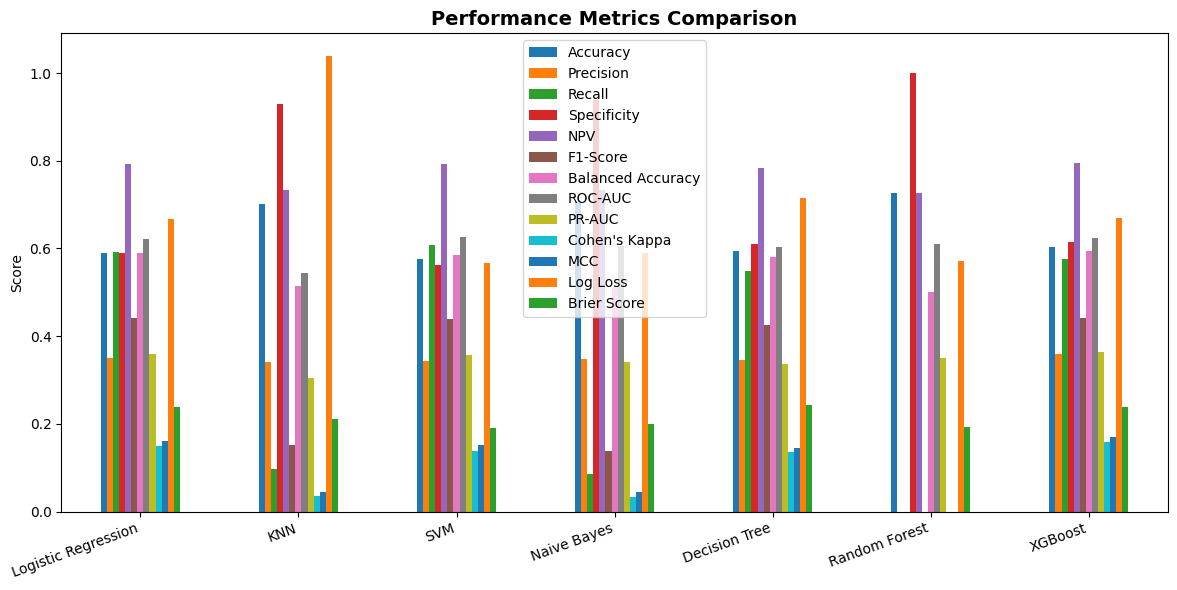

In [48]:
metrics_df = pd.DataFrame({k: {mk: mv for mk, mv in v.items() if mk not in ['y_pred', 'y_prob', 'model']}
                           for k, v in eval_metrics.items()}).T
plt.figure(figsize=(12, 6))
metrics_df.plot(kind='bar', ax=plt.gca())
plt.title('Performance Metrics Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('1_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

#### **ROC Curves**

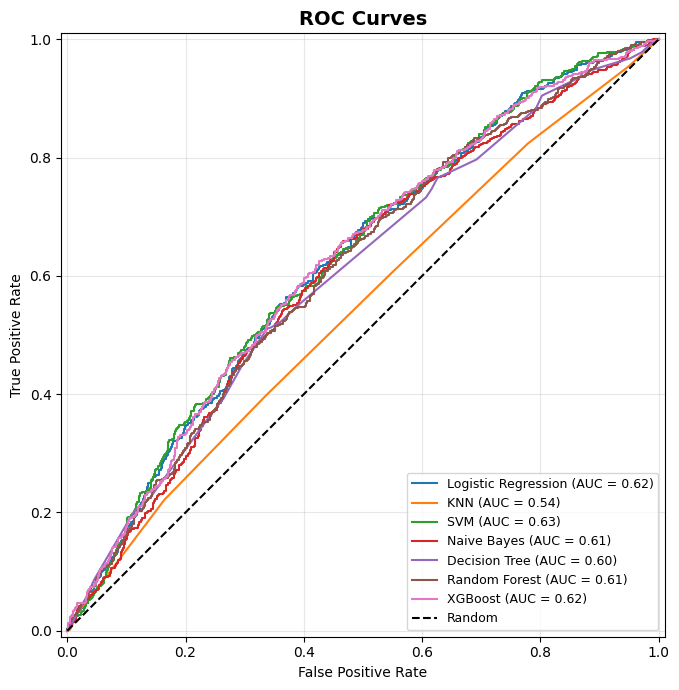

In [49]:
plt.figure(figsize=(9, 7))
for name, res in eval_metrics.items():
    RocCurveDisplay.from_predictions(y_test, res['y_prob'], name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.title('ROC Curves', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('2_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

#### **Precision-Recall Curves**

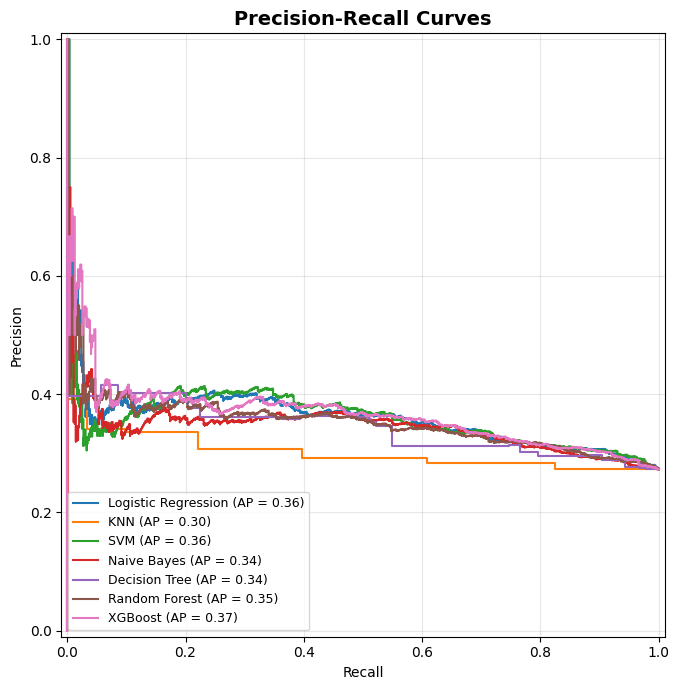

In [50]:
plt.figure(figsize=(9, 7))
for name, res in eval_metrics.items():
    PrecisionRecallDisplay.from_predictions(y_test, res['y_prob'], name=name, ax=plt.gca())
plt.title('Precision-Recall Curves', fontsize=14, fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('3_pr_curves.png', dpi=300, bbox_inches='tight')
plt.show()

#### **Learning Curve for best model**

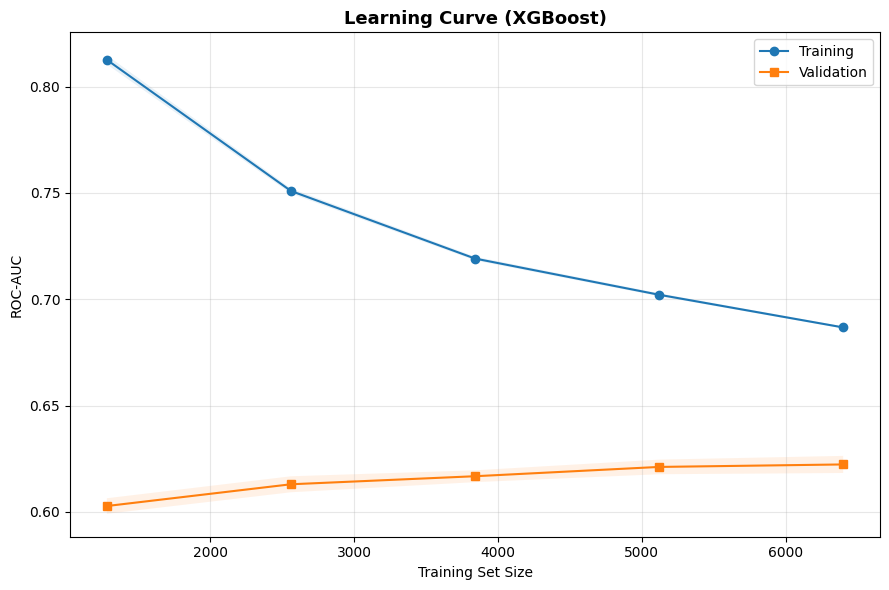

In [51]:
best_name = max(eval_metrics, key=lambda k: eval_metrics[k]['PR-AUC'])
plt.figure(figsize=(9, 6))
train_sizes, train_scores, val_scores = learning_curve(
    eval_metrics[best_name]['model'], X_train, y_train, cv=cv,
    scoring='roc_auc', n_jobs=-1, train_sizes=np.linspace(0.2, 1.0, 5))
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', label='Training')
plt.plot(train_sizes, np.mean(val_scores, axis=1), 's-', label='Validation')
plt.fill_between(train_sizes,
                 np.mean(train_scores, axis=1) - np.std(train_scores, axis=1)/2,
                 np.mean(train_scores, axis=1) + np.std(train_scores, axis=1)/2, alpha=0.1)
plt.fill_between(train_sizes,
                 np.mean(val_scores, axis=1) - np.std(val_scores, axis=1)/2,
                 np.mean(val_scores, axis=1) + np.std(val_scores, axis=1)/2, alpha=0.1)
plt.title(f'Learning Curve ({best_name})', fontsize=13, fontweight='bold')
plt.xlabel('Training Set Size')
plt.ylabel('ROC-AUC')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('5_learning_curve.png', dpi=300, bbox_inches='tight')
plt.show()

### **STAGE 9: FEATURE IMPORTANCE**

### **Feature importance from best tree-based model**

#### **Get fitted models**

In [55]:
xgb_pipeline = eval_metrics['XGBoost']['model']
rf_pipeline = eval_metrics['Random Forest']['model']

xgb_model = xgb_pipeline.named_steps['xgb']
rf_model = rf_pipeline.named_steps['rf']

##### **Get the fitted preprocessor**

In [56]:
preprocessor = xgb_pipeline.named_steps['preprocessor']

##### **Get ACTUAL feature names after preprocessing**

In [57]:
feature_names = preprocessor.get_feature_names_out()

print(f"Number of transformed features: {len(feature_names)}")
print(feature_names)

Number of transformed features: 28
['nominal__Gender_Female' 'nominal__Gender_Male'
 'nominal__Marital_Status_Divorced' 'nominal__Marital_Status_Married'
 'nominal__Marital_Status_Single' 'nominal__Employment_Status_Employed'
 'nominal__Employment_Status_Self-employed'
 'nominal__Employment_Status_Unemployed' 'nominal__Account_Type_Current'
 'nominal__Account_Type_Fixed Deposit' 'nominal__Account_Type_Savings'
 'nominal__Email_Opt_In_0' 'nominal__Email_Opt_In_1'
 'nominal__Credit_Card_Holder_0' 'nominal__Credit_Card_Holder_1'
 'nominal__Loan_Account_Holder_0' 'nominal__Loan_Account_Holder_1'
 'ordinal__Education_Level' 'numeric__Age'
 'numeric__Account_Tenure_Months' 'numeric__Number_of_Products'
 'numeric__Average_Balance' 'numeric__Monthly_Transactions'
 'numeric__Online_Banking_Usage' 'numeric__Mobile_Banking_Usage'
 'numeric__Number_of_Complaints' 'numeric__Complaint_Resolution_Rate'
 'numeric__Customer_Support_Calls']


##### **XGBoost Feature Importance**

In [59]:
xgb_imp = pd.Series(
    xgb_model.feature_importances_,
    index=feature_names
).sort_values(ascending=True)

##### **Random Forest Feature Importance**

In [60]:
rf_imp = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=True)

##### **Plot**

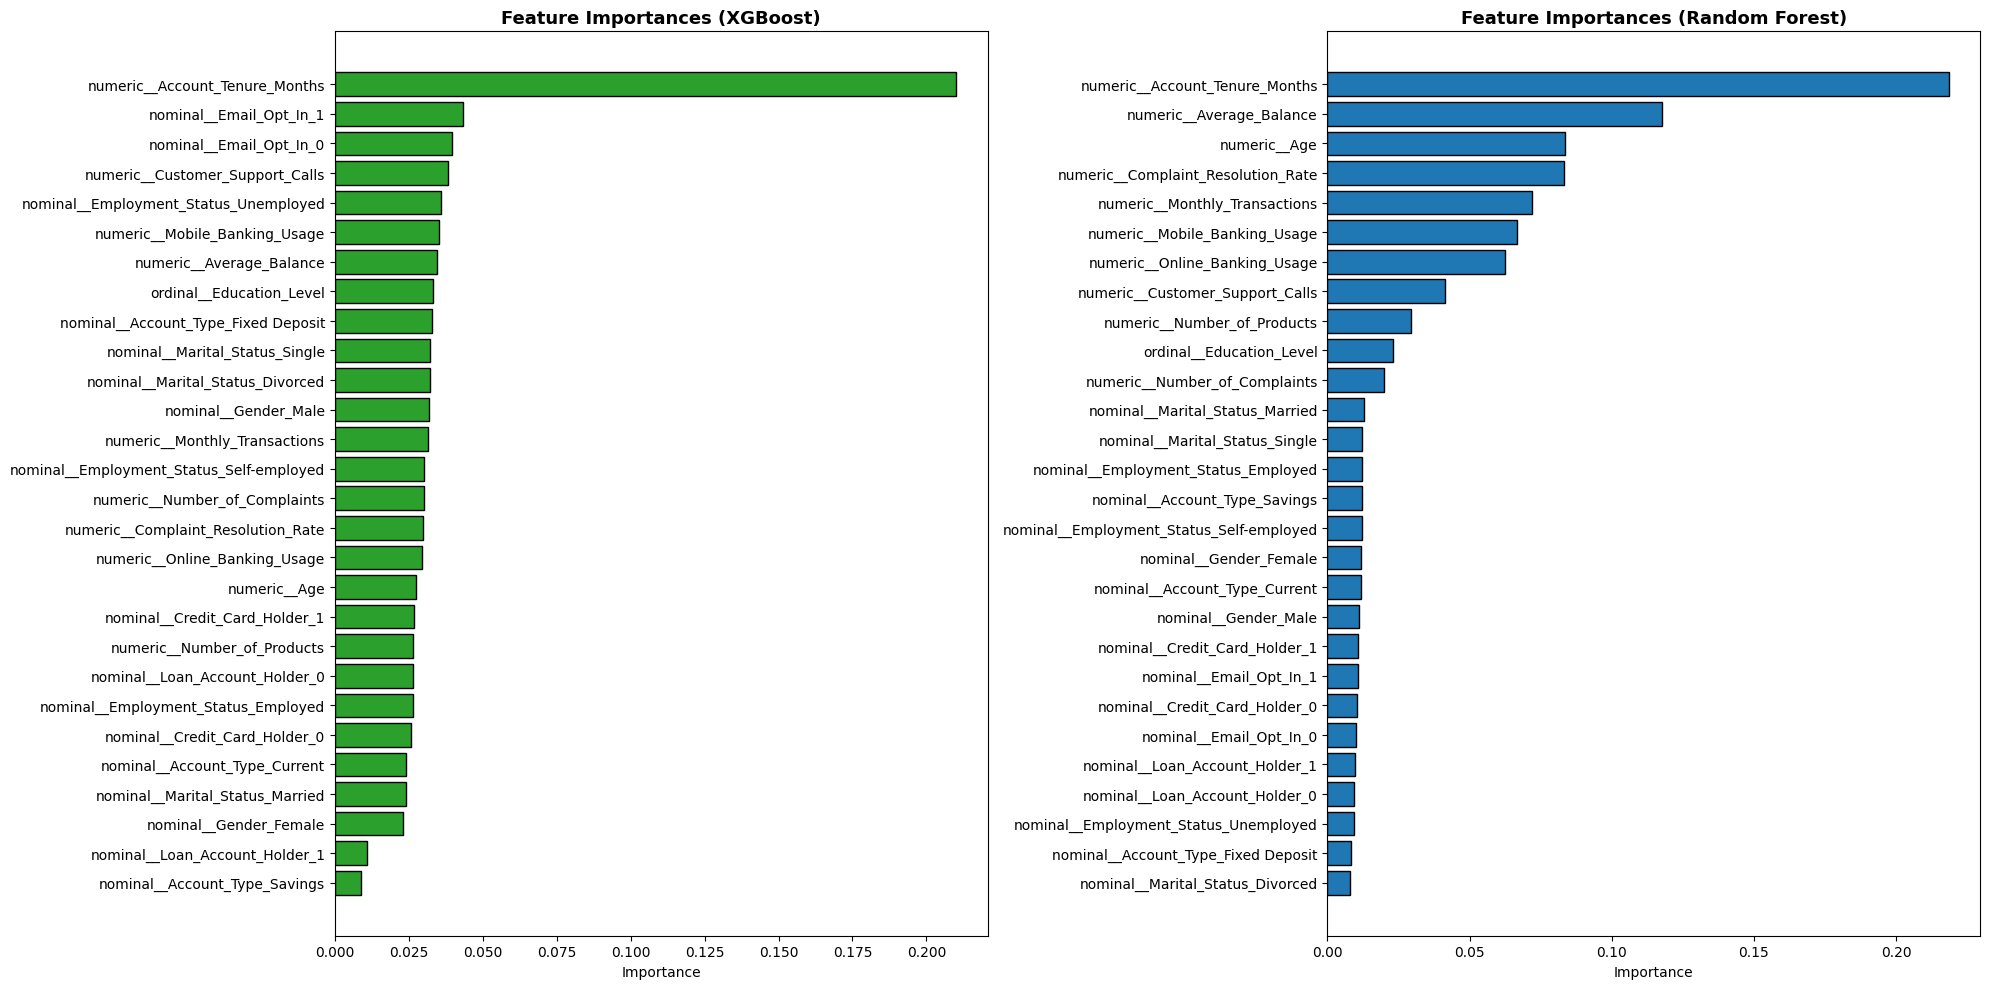

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].barh(xgb_imp.index, xgb_imp.values, color='#2ca02c', edgecolor='black')

axes[0].set_title('Feature Importances (XGBoost)',fontsize=13,fontweight='bold')
axes[0].set_xlabel('Importance')

axes[1].barh(rf_imp.index, rf_imp.values, color='#1f77b4', edgecolor='black')
axes[1].set_title('Feature Importances (Random Forest)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.savefig('6_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

### **STAGE 10: MODEL SELECTION & FINAL RECOMMENDATION**

In [ ]:
best_name = max(eval_metrics, key=lambda k: eval_metrics[k]['PR-AUC'])
print("\n" + "="*110)
print(f"🏆 SELECTED MODEL: {best_name}")
print("="*110)
print(f"  Accuracy:  {eval_metrics[best_name]['Accuracy']:.4f}")
print(f"  Precision: {eval_metrics[best_name]['Precision']:.4f}")
print(f"  Recall:    {eval_metrics[best_name]['Recall']:.4f}")
print(f"  F1-Score:  {eval_metrics[best_name]['F1-Score']:.4f}")
print(f"  ROC-AUC:   {eval_metrics[best_name]['ROC-AUC']:.4f}")
print(f"  PR-AUC:    {eval_metrics[best_name]['PR-AUC']:.4f}")
print("="*110)


🏆 SELECTED MODEL: XGBoost
  Accuracy:  0.6035
  Precision: 0.3589
  Recall:    0.5751
  F1-Score:  0.4419
  ROC-AUC:   0.6232
  PR-AUC:    0.3635


#### **Features Importance for the Best Model**

Number of transformed features: 28
['nominal__Gender_Female' 'nominal__Gender_Male'
 'nominal__Marital_Status_Divorced' 'nominal__Marital_Status_Married'
 'nominal__Marital_Status_Single' 'nominal__Employment_Status_Employed'
 'nominal__Employment_Status_Self-employed'
 'nominal__Employment_Status_Unemployed' 'nominal__Account_Type_Current'
 'nominal__Account_Type_Fixed Deposit' 'nominal__Account_Type_Savings'
 'nominal__Email_Opt_In_0' 'nominal__Email_Opt_In_1'
 'nominal__Credit_Card_Holder_0' 'nominal__Credit_Card_Holder_1'
 'nominal__Loan_Account_Holder_0' 'nominal__Loan_Account_Holder_1'
 'ordinal__Education_Level' 'numeric__Age'
 'numeric__Account_Tenure_Months' 'numeric__Number_of_Products'
 'numeric__Average_Balance' 'numeric__Monthly_Transactions'
 'numeric__Online_Banking_Usage' 'numeric__Mobile_Banking_Usage'
 'numeric__Number_of_Complaints' 'numeric__Complaint_Resolution_Rate'
 'numeric__Customer_Support_Calls']

Number of coefficients: 28
Number of feature names: 28


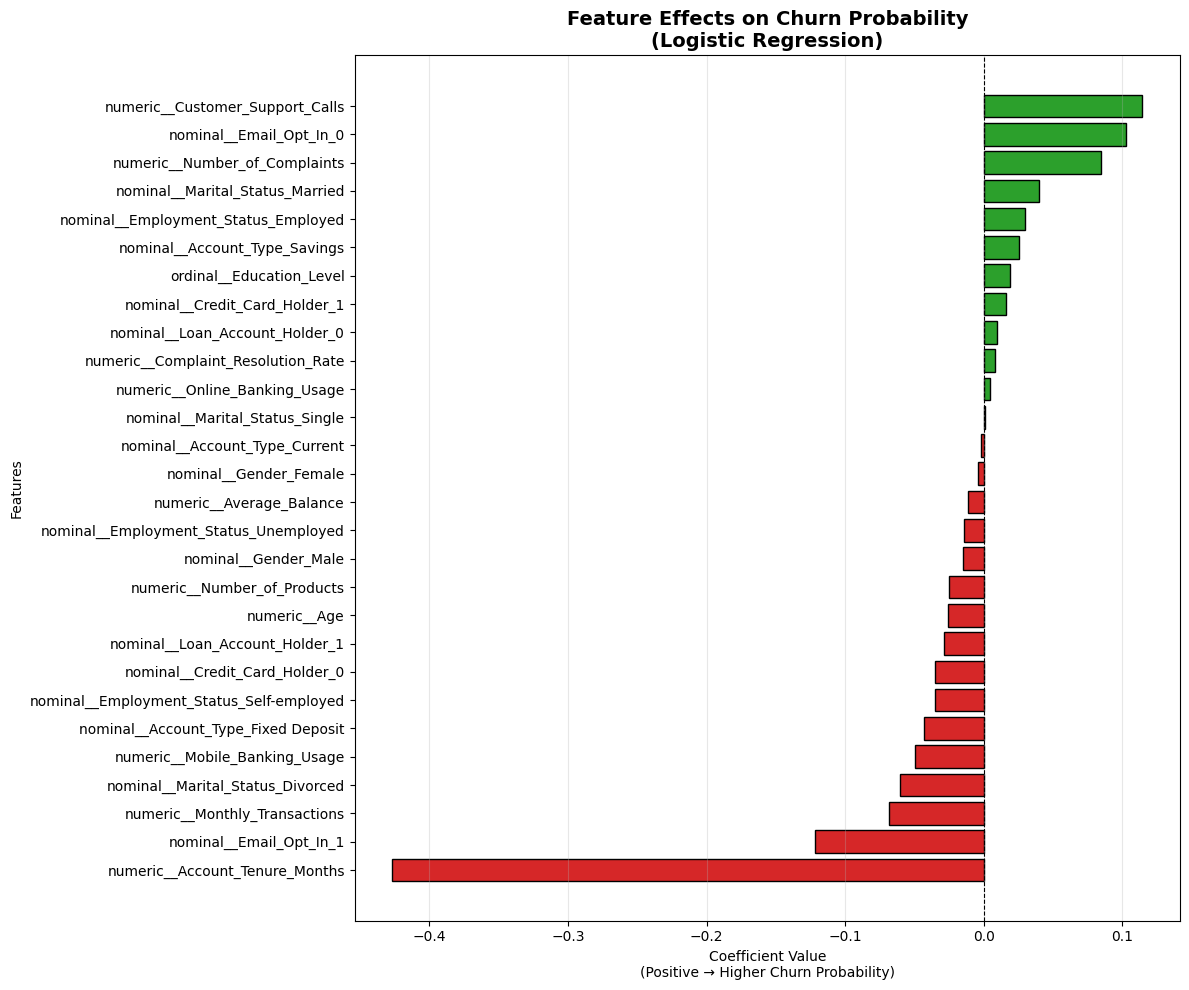

In [68]:
lr_pipeline = eval_metrics['Logistic Regression']['model']
lr_model = lr_pipeline.named_steps['lr']
preprocessor = lr_pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

print(f"Number of transformed features: {len(feature_names)}")
print(feature_names)

lr_coef = lr_model.coef_[0]

print(f"\nNumber of coefficients: {len(lr_coef)}")
print(f"Number of feature names: {len(feature_names)}")

lr_imp = pd.Series(lr_coef, index=feature_names)

lr_imp_signed = lr_imp.sort_values(ascending=True)

plt.figure(figsize=(12, 10))

colors = ['#d62728' if value < 0 else '#2ca02c' for value in lr_imp_signed.values]

plt.barh(lr_imp_signed.index, lr_imp_signed.values, color=colors, edgecolor='black'
)

plt.axvline(x=0, color='black', linewidth=0.8, linestyle='--')

plt.title('Feature Effects on Churn Probability\n(Logistic Regression)',
    fontsize=14,fontweight='bold'
)

plt.xlabel('Coefficient Value\n(Positive → Higher Churn Probability)')
plt.ylabel('Features')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('6_feature_importance_lr_signed.png',dpi=300,bbox_inches='tight')
plt.show()

#### **PLOT 2: Absolute Coefficients**

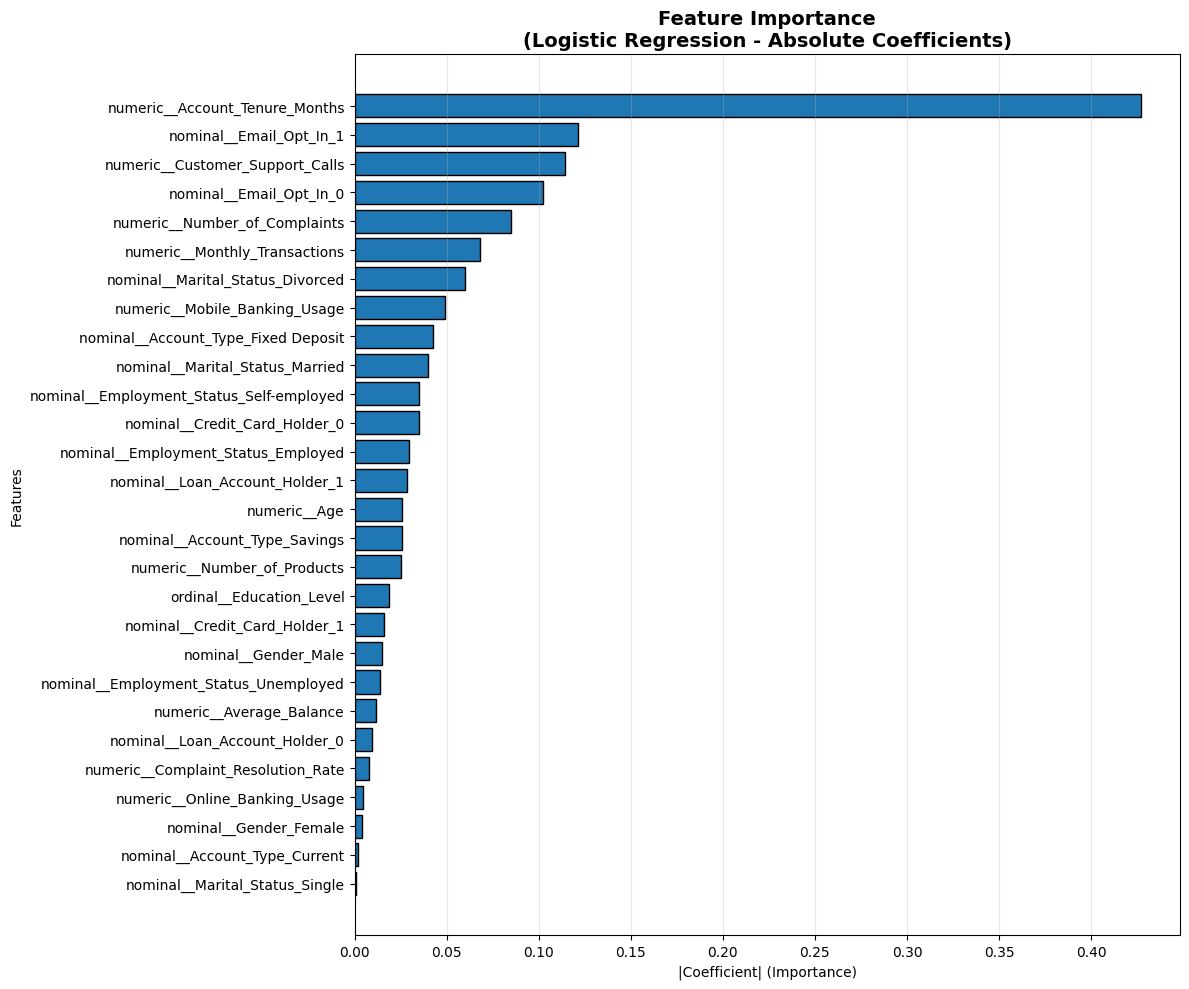

In [69]:
lr_imp_abs = lr_imp.abs().sort_values(ascending=True)
plt.figure(figsize=(12, 10))
plt.barh(lr_imp_abs.index, lr_imp_abs.values, color='#1f77b4', edgecolor='black')
plt.title('Feature Importance\n(Logistic Regression - Absolute Coefficients)',
    fontsize=14,fontweight='bold')
plt.xlabel('|Coefficient| (Importance)')
plt.ylabel('Features')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('6_feature_importance_lr_absolute.png', dpi=300,bbox_inches='tight')
plt.show()

### **STAGE 11: CONCLUSION & DISCUSSION**

#### **Summary of Findings**

This project developed an end-to-end machine learning pipeline for predicting customer churn using demographic, account, behavioural, and service-interaction characteristics. The dataset used in the analysis was obtained from Kaggle:

**Dataset:** [Customer Churn Prediction Dataset – Kaggle](https://www.kaggle.com/datasets/lumumbavictor/customer-churn-prediction)

Seven classification algorithms were trained and optimized using **stratified 5-fold cross-validation** with `RandomizedSearchCV`. The models were subsequently evaluated on a held-out test set using **ROC-AUC, PR-AUC, Recall, and Precision**. This provided a comprehensive assessment of predictive performance while accounting for the moderate class imbalance in the churn outcome (~27.3% churn rate).

#### **Key Results**

| Model | ROC-AUC | PR-AUC | Recall | Precision |
| :--- | :---: | :---: | :---: | :---: |
| **XGBoost** | **0.6232** | **0.3635** | **0.5751** | **0.3589** |
| Logistic Regression | 0.6223 | 0.3594 | 0.5916 | 0.3511 |
| SVM | 0.6253 | 0.3573 | 0.6081 | 0.3430 |
| Random Forest | 0.6101 | 0.3513 | 0.0000 | 0.0000 |
| Naive Bayes | 0.6066 | 0.3414 | 0.0861 | 0.3481 |
| Decision Tree | 0.6028 | 0.3368 | 0.5495 | 0.3464 |
| KNN | 0.5440 | 0.3049 | 0.0971 | 0.3419 |

*Note: **XGBoost** was selected as the final model due to achieving the highest PR-AUC (0.3635), which is the most critical metric for imbalanced datasets where identifying the minority class (churners) accurately is prioritized over overall accuracy.*

#### **Strengths of the Solution**

* **Reproducible pipeline:** All preprocessing steps (imputation, scaling, encoding) were incorporated into scikit-learn pipelines, minimizing the risk of data leakage and ensuring consistency between training and prediction.
* **Stratified evaluation:** Stratified cross-validation and train-test splitting preserved the ~27% distribution of churn observations across all folds and sets.
* **Multiple models compared:** Seven diverse classification algorithms (linear, distance-based, and tree-based ensembles) were evaluated, providing a robust basis for model selection.
* **Class imbalance addressed:** Class-weighting techniques, including `class_weight='balanced'` and XGBoost's `scale_pos_weight`, were utilized to penalize misclassifications of the minority class more heavily.
* **Comprehensive evaluation:** Relying on PR-AUC and Recall rather than just Accuracy prevented the models from simply defaulting to predicting the majority class (non-churners).

#### **Limitations**

* **Modest Predictive Performance:** The highest ROC-AUC achieved was ~0.62, and PR-AUC was ~0.36. This indicates that while the models captured some signal, the available static features alone are weak predictors of churn. The high rate of false positives (Precision ~35%) means many retained customers would receive unnecessary interventions if deployed blindly.
* **No temporal validation:** The dataset does not provide a sufficiently structured temporal sequence for time-based validation. In a real-world setting, temporal train-test splits would provide a stronger assessment of future predictive performance.
* **Single customer snapshot:** The dataset contains limited longitudinal information about individual customer behaviour and customer journeys over time.
* **Limited feature engineering:** Additional features, such as transaction trends, changes in account balances, recent spikes in support calls, or competitor pricing data, are likely needed to significantly boost predictive power.
* **Threshold selection:** The final classification threshold was left at the default 0.50. A custom threshold optimized for the specific business costs of false positives vs. false negatives is required for production.

#### **Business Recommendations**

1. **Use as a Prioritization Flag, Not an Automated Trigger:** Given the precision of ~35%, the model should not automatically trigger expensive retention offers. Instead, it should flag "at-risk" accounts for low-cost automated check-ins (e.g., satisfaction surveys) or human review by account managers.
2. **Improve Data Collection:** The modest model performance suggests that static demographic and account features are insufficient. The business should invest in capturing real-time behavioural data, transaction velocity, and digital engagement metrics.
3. **Address Root Causes of Churn:** Feature importance analysis highlights service friction. Management should focus operationally on reducing `Number_of_Complaints` and improving the `Complaint_Resolution_Rate`, as these are direct drivers of customer attrition.
4. **Target Low-Tenure Customers:** The data suggests newer customers are more volatile. Implementing a structured 90-day onboarding and success program could organically reduce early-stage churn without relying solely on ML predictions.
5. **Conduct a Cost-Benefit Analysis:** Before scaling, calculate the exact ROI. If the cost of a retention campaign is high, a 35% precision rate may result in a negative ROI. The threshold must be adjusted to balance campaign costs against the Customer Lifetime Value (CLV) of saved accounts.

#### **Explainability**

Although tree-based ensembles like **XGBoost** were selected for their superior predictive performance, they still offer valuable insights through feature importance analysis. Analysis of the selected XGBoost model indicates that `Number_of_Complaints`, `Complaint_Resolution_Rate`, `Customer_Support_Calls`, and `Account_Tenure_Months` are among the strongest predictors of customer churn.

These findings are consistent with business expectations. Customers experiencing repeated problems, frequent support interactions, or unresolved complaints have a mathematically higher probability of leaving. Model explainability is crucial here because it allows customer-retention teams to understand **why** a customer has been classified as high risk (e.g., "This customer has 3 unresolved complaints") and supports targeted, empathetic outreach rather than generalized discount offers.

#### **Deployment Decision**

**Conditional Deployment / Pilot Phase Recommended.**

The selected model demonstrates *modest* discriminatory ability (ROC-AUC = 0.6232, PR-AUC = 0.3635). It performs better than random guessing and captures meaningful business signals regarding customer friction, but it is **not** currently accurate enough to serve as a fully automated, high-cost decision engine. 

Before full-scale implementation, the following steps are mandatory:
1. **Cost-Benefit & Threshold Optimization:** Conduct a financial simulation to identify the probability threshold that maximizes ROI. The business must weigh the cost of false-positive retention campaigns against the lost revenue of false-negative churners.
2. **A/B Testing:** Run a controlled pilot where a subset of model-flagged customers receives a specific intervention, while a control group receives standard treatment. This will empirically prove whether model-driven strategies actually reduce churn.
3. **Feature Augmentation:** Retrain the model incorporating richer behavioural and temporal features to push the ROC-AUC above the 0.75+ threshold typically required for reliable automated deployment.

#### **References**

1. **Dataset:** Blastchar. *Telco Customer Churn Dataset*. Kaggle. [Customer Churn Prediction](https://www.kaggle.com/datasets/lumumbavictor/customer-churn-prediction)
2. **Scikit-learn Documentation:** [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)
3. **XGBoost Documentation:** [https://xgboost.readthedocs.io/](https://xgboost.readthedocs.io/)
4. Lundberg, S. M., & Lee, S.-I. (2017). *A unified approach to interpreting model predictions*. Advances in Neural Information Processing Systems.
5. Gisma University of Applied Sciences. *M505 Assessment Brief & Additional Hints*.